<a href="https://colab.research.google.com/github/ThuyLienNguyen/FSVRG-ADMM/blob/main/FSVRG_5_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FSVRG-ADMM: a reproducible favorable example

**Run all cells using a CPU runtime.** Everything needed for the experiment is
embedded below; no data upload, external script, GPU, or Google Drive mount is
required. The setup cell installs a dependency only if it is missing or too old.

This experiment compares six methods on

$$\min_{x=y}\;\frac{1}{2n}\|Dx-b\|^2+\frac{\mu}{2}\|y\|^2,$$

with $n=2048$, $d=20$, $\mu=10^{-4}$, and a dense correlated Gaussian design
whose population covariance eigenvalues range from $1$ to $10^{-3}$.
This is the manuscript's specialization $A=I$, $B=-I$, $c=0$,
$g(y)=\mu\|y\|^2/2$, and $h=0$. It isolates gradient momentum; it does not
test the nonsmooth DC extension. The proposed updates use $\theta=\eta=1$.

The exact ridge minimizer is used only for monitoring. All algorithms start at
zero and must meet **both** relative solution error and relative feasibility
at most $10^{-3}$. The main cost is component-gradient evaluations divided by
$n$: each snapshot costs $n$, and each SVRG minibatch difference costs $2b$,
where $b=32$. Every method uses the same algebraic shortcut for quadratic
gradient differences. Solver timing excludes monitoring and common data setup.

The example family was chosen through pilot exploration. Hyperparameters were
selected on data seed 123 and sampling seed 7, then frozen before testing the
five data seeds 1001--1005 and sampling seeds 41, 43, 47. The full run contains
15 data/sampling pairs per method. These are five independent datasets with
three sampling runs each, not 15 independent datasets. The full-gradient
ablation is deterministic and repeats the same trajectory for the three
sampling seeds on each dataset.

## Measured reference results

All six methods met both tolerances in all 15 pairs in the local validation run.
Median gradient passes were:

| Method | Median passes |
|---|---:|
| SVRG-ADMM (2016) | 216 |
| ASVRG-ADMM (2021) | 237 |
| Relaxed SVRG ablation | 135 |
| Full-gradient ablation | 2272 |
| **FSVRG-ADMM** | **54** |
| **AFSVRG-ADMM** | **54** |

FSVRG used fewer gradient evaluations than each comparator in all 15 paired
runs. These results concern the frozen finite-grid settings on this chosen
problem family. The parameters are empirical choices, not a certification
of the manuscript's sufficient convergence inequalities. The direct ridge
solution is available for this small problem; this experiment compares the
specified iterative methods. Elapsed times depend on the runtime.

## Published baselines

- Zheng and Kwok, *Fast-and-Light Stochastic ADMM*, IJCAI 2016,
  [Algorithm 1](https://cse.hkust.edu.hk/faculty/jamesk/papers/ijcai16a.pdf).
- Liu et al., *Accelerated Variance Reduction Stochastic ADMM for Large-Scale
  Machine Learning*, TPAMI 43(12), 2021,
  [strongly convex Algorithm 1](https://zhouchenlin.github.io/Publications/2020-TPAMI-ASVRG-ADMM.pdf).

The code preserves their epoch averages and dual resets. The ASVRG inner dual
update is taken from Algorithm 2 and the proof of Lemma 3, because that line is
omitted from the strongly convex algorithm box. The two other comparators are
explicitly labeled ablations. The fixed FSVRG setting has $\alpha=1/2$, so its
advantage in this experiment primarily demonstrates gradient momentum.


## 1. Dependencies


In [ ]:
import importlib.metadata
import re
import subprocess
import sys

minimum_versions = {
    "numpy": (1, 23), "pandas": (1, 5),
    "matplotlib": (3, 7), "threadpoolctl": (3, 1),
}
needed = []
for package, minimum in minimum_versions.items():
    try:
        current = tuple(map(int, re.findall(r"\d+", importlib.metadata.version(package))[:2]))
        if current < minimum:
            needed.append(f"{package}>={minimum[0]}.{minimum[1]}")
    except importlib.metadata.PackageNotFoundError:
        needed.append(f"{package}>={minimum[0]}.{minimum[1]}")
if needed:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *needed])
print("Dependencies ready:", {p: importlib.metadata.version(p) for p in minimum_versions})


Dependencies ready: {'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'threadpoolctl': '3.7.0'}


## 2. Complete algorithm implementations

The source below also contains algebra and rotation-invariance checks.


In [ ]:
"""A measured favorable regime for FSVRG-ADMM: ill-conditioned ridge regression.

Self-contained, CPU-only; paste into Colab or upload and use:
    %run fsvrg_advantage_colab.py --mode full --show
    %run fsvrg_advantage_colab.py --mode quick --show

Original problem: min ||D x-b||^2/(2n) + mu*||y||^2/2, x-y=0.
New-method specialization: theta=eta=1, Q_y=q_y I, Q_z=q_z I, h=0.
This isolates the gradient-momentum mechanism, not nonsmooth DC modeling.

Published baselines:
Zheng & Kwok, IJCAI 2016, Algorithm 1 (G=I):
https://cse.hkust.edu.hk/faculty/jamesk/papers/ijcai16a.pdf
Liu et al., TPAMI 2021, strongly convex ASVRG Algorithm 1 (B=-I):
https://zhouchenlin.github.io/Publications/2020-TPAMI-ASVRG-ADMM.pdf
The latter's omitted inner dual line is supplied by its Algorithm 2 and
Lemma 3 proof: u_new=u_old+z_new-y_new. Here nu=-rho*u.

All stochastic methods use independent uniform subset minibatches. We charge
n for every full snapshot and 2*b for each raw SVRG minibatch difference.
The exact quadratic difference is fused algebraically for all methods.
The reference solution/Gram matrix is used ONLY for monitoring and data
description; full optimizer gradients are evaluated from the original data.

Parameters were selected on pilot data seed123, sampling seed7. Default test
data seeds1001..1005 and sampling seeds41,43,47 were excluded from tuning.
This is a finite-sum algorithm benchmark, not a claim to beat a direct ridge
solver or every possible hyperparameter setting.
"""

from __future__ import annotations

import argparse
import json
import time
from dataclasses import dataclass, asdict
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None


@dataclass(frozen=True)
class Config:
    name: str
    family: str                # "ours", "published", or "full"
    rho: float
    qz: float
    beta: float = 1.0
    alpha: float | str = 0.5
    theta: float = 1.0
    qy: float = 0.01
    m: int = 64


# Frozen BEFORE the final data seeds below were evaluated.
CONFIGS = [
    Config("SVRG-ADMM (2016)", "published", 0.1, 0.5, qy=0.0, m=256),
    Config("ASVRG-ADMM (2021)", "published", 0.01, 0.2, theta=0.4, qy=0.0),
    Config("Relaxed SVRG ablation", "ours", 0.1, 0.5, alpha=0.75),
    Config("Full-gradient ablation", "full", 0.1, 0.4, alpha=0.75),
    Config("FSVRG-ADMM (ours)", "ours", 0.1, 0.1, beta=0.2, alpha=0.5),
    Config("AFSVRG-ADMM (ours)", "ours", 0.01, 0.2, beta=0.2, alpha="adaptive"),
]
TEST_DATA_SEEDS = [1001, 1002, 1003, 1004, 1005]
TEST_SAMPLING_SEEDS = [41, 43, 47]


def make_problem(data_seed, n=2048, d=20, condition=1000.0, mu=1e-4):
    """Dense correlated Gaussian design with a prescribed population spectrum."""
    rng = np.random.default_rng(data_seed)
    raw = rng.normal(size=(n, d)) * np.sqrt(np.geomspace(1.0, 1.0/condition, d))
    truth_raw = rng.normal(size=d)
    b = raw @ truth_raw + 0.01 * rng.normal(size=n)
    # Orthogonal rotation prevents the conditioning from being just a matter
    # of marginal column scales. Scalar-proximal methods are rotation invariant.
    rotation_rng = np.random.default_rng(data_seed + 100000)
    U, _ = np.linalg.qr(rotation_rng.normal(size=(d, d)))
    D = raw @ U.T
    H = D.T @ D/n + mu*np.eye(d)
    rhs = D.T @ b/n
    x_star = np.linalg.solve(H, rhs)
    assert np.linalg.norm(H @ x_star-rhs) <= 1e-11 * max(1.0, np.linalg.norm(rhs))
    return {
        "D": D, "b": b, "mu": mu, "H": H, "rhs": rhs,
        "x_star": x_star, "data_seed": int(data_seed),
        "condition": float(np.linalg.cond(H)),
    }


def measure(problem, x, y):
    """True minimizer error, feasibility, and numerically stable objective gap."""
    ref = problem["x_star"]
    error = x-ref
    error0 = max(np.linalg.norm(ref), np.finfo(float).tiny)
    gap0 = max(0.5 * ref @ problem["H"] @ ref, np.finfo(float).tiny)
    return {
        "relative_error": float(np.linalg.norm(error)/error0),
        "feasibility": float(np.linalg.norm(x-y)/max(1.0, np.linalg.norm(x))),
        "relative_objective_gap": float(0.5 * error @ problem["H"] @ error/gap0),
    }


def solve(problem, cfg, sampling_seed=41, batch=32, max_passes=4000,
          tolerance=1e-3):
    """Stop on BOTH reference-solution error and feasibility, or on the budget."""
    D, b, mu = problem["D"], problem["b"], problem["mu"]
    n, d = D.shape
    if not (0 < cfg.rho and 0 < cfg.qz and 0 < cfg.beta <= 1
            and 0 < cfg.theta <= 1 and 1 <= batch <= n and cfg.m > 0):
        raise ValueError("Invalid method or sampling parameters.")
    if cfg.family not in ("ours", "full", "published"):
        raise ValueError("Unknown algorithm family.")
    if cfg.family != "published" and cfg.theta != 1.0:
        raise ValueError("This benchmark specializes the new method to theta=1.")
    rng = np.random.default_rng(sampling_seed)
    x = np.zeros(d)
    y, nu = x.copy(), x.copy()
    v = None
    calls = 0
    iterations = 0
    solver_seconds = 0.0
    monitor_seconds = 0.0
    history = []
    wall_start = time.perf_counter()
    status = "budget_exhausted"
    max_adaptive_violation = 0.0

    def record():
        nonlocal monitor_seconds
        start = time.perf_counter()
        row = measure(problem, x, y)
        monitor_seconds += time.perf_counter()-start
        row.update({
            "method": cfg.name, "data_seed": problem["data_seed"],
            "sampling_seed": sampling_seed, "iterations": iterations,
            "gradient_evaluations": calls, "passes": calls/n,
            "solver_seconds": solver_seconds, "monitor_seconds": monitor_seconds,
            "wall_seconds": time.perf_counter()-wall_start,
        })
        history.append(row)
        return row["relative_error"] <= tolerance and row["feasibility"] <= tolerance

    record()
    while calls < int(max_passes*n):
        start = time.perf_counter()
        if cfg.family == "full":
            steps = min(16, int(max_passes*n-calls)//n)
            if steps == 0:
                break
        else:
            # Published methods return epoch averages, so do complete epochs.
            epoch_cost = n+2*batch*cfg.m
            if calls+epoch_cost > int(max_passes*n):
                break
            snapshot = x.copy()
            full_snapshot = D.T @ (D @ snapshot-b)/n
            calls += n
            steps = cfg.m
            if cfg.family == "published":
                z = snapshot.copy()
                nu = full_snapshot.copy()       # source-prescribed epoch reset
                old_y_snapshot = y.copy()
                sum_x, sum_y = np.zeros(d), np.zeros(d)
            elif v is None:
                v = full_snapshot.copy()        # reuse first snapshot, then carry

        failed = False
        for _ in range(steps):
            if cfg.family == "full":
                raw_gradient = D.T @ (D @ x-b)/n
                calls += n
            else:
                indices = rng.choice(n, size=batch, replace=False)
                Db = D[indices]
                raw_gradient = Db.T @ (Db @ (x-snapshot))/batch + full_snapshot
                calls += 2*batch

            if cfg.family == "published":
                # For theta=1 this is Zheng--Kwok SVRG with G=I.
                # For theta<1 this is Liu et al. strongly convex ASVRG.
                y = (cfg.rho*z-nu)/(cfg.rho+mu)
                z = (cfg.qz*z-raw_gradient+cfg.rho*y+nu)/(cfg.rho+cfg.qz)
                x = (1.0-cfg.theta)*snapshot + cfg.theta*z
                nu = nu-cfg.rho*(z-y)
                sum_x += x
                sum_y += y
            else:
                if cfg.family == "full":
                    v = raw_gradient
                else:
                    v = (1.0-cfg.beta)*v+cfg.beta*raw_gradient
                y_new = (cfg.rho*x-nu+cfg.qy*y)/(cfg.rho+cfg.qy+mu)
                r_old = x-y_new
                x_half = (-v+nu+cfg.rho*y_new+cfg.qz*x)/(cfg.rho+cfg.qz)
                if cfg.alpha == "adaptive":
                    direction = 2.0*cfg.rho*r_old/(cfg.rho+cfg.qz)
                    denom = float(direction @ direction)
                    offset = float((x_half-y_new) @ direction/denom) if denom > 0 else 0.0
                    alpha = 0.5+float(np.clip(offset, -0.4, 0.4))
                else:
                    alpha = float(cfg.alpha)
                x_new = x_half-cfg.rho*(2.0*alpha-1.0)*r_old/(cfg.rho+cfg.qz)
                nu = nu-cfg.rho*(x_new-y_new)-cfg.rho*(2.0*alpha-1.0)*r_old
                if cfg.alpha == "adaptive":
                    violation = np.linalg.norm(x_new-y_new)-np.linalg.norm(x_half-y_new)
                    max_adaptive_violation = max(max_adaptive_violation, float(violation))
                    if violation > 1e-10*(1+np.linalg.norm(x_half-y_new)):
                        raise AssertionError("Same-state adaptive minimization failed.")
                x, y = x_new, y_new
            iterations += 1
            if not np.all(np.isfinite(x)) or np.linalg.norm(x) > 1e10:
                failed = True
                status = "numerical_failure"
                break
        if cfg.family == "published" and not failed:
            x = sum_x/cfg.m
            y = (1.0-cfg.theta)*old_y_snapshot + cfg.theta*sum_y/cfg.m
        solver_seconds += time.perf_counter()-start
        if failed:
            break
        if record():
            status = "converged"
            break

    result = history[-1].copy()
    if status == "numerical_failure":
        # Do not present the last finite checkpoint as the failed iterate.
        result.update({
            "relative_error": np.nan, "feasibility": np.nan,
            "relative_objective_gap": np.nan, "iterations": iterations,
            "gradient_evaluations": calls, "passes": calls/n,
            "solver_seconds": solver_seconds, "monitor_seconds": monitor_seconds,
            "wall_seconds": time.perf_counter()-wall_start,
        })
        history.append(result.copy())
    result.update({
        "status": status, "reached_tolerance": status == "converged",
        "passes_to_tolerance": calls/n if status == "converged" else np.nan,
        "time_to_tolerance": solver_seconds if status == "converged" else np.nan,
        "evaluated_passes": calls/n, "tolerance": tolerance,
        "condition_number": problem["condition"],
        "max_adaptive_violation": max_adaptive_violation,
    })
    return pd.DataFrame(history), result


def validation_checks():
    """Checks algebra, exact-reference accuracy and orthogonal invariance."""
    p = make_problem(123)
    rng = np.random.default_rng(71)
    x = rng.normal(size=len(p["x_star"]))
    e = rng.normal(size=len(x))
    e /= np.linalg.norm(e)
    eps = 1e-6
    f = lambda q: np.mean((p["D"] @ q-p["b"])**2)/2
    grad = p["D"].T @ (p["D"] @ x-p["b"])/len(p["b"])
    np.testing.assert_allclose((f(x+eps*e)-f(x-eps*e))/(2*eps), grad @ e,
                               rtol=1e-6, atol=1e-8)
    # The closed-form ridge point is a fixed point of both update conventions.
    x = p["x_star"]
    mu = p["mu"]
    nu = -mu*x
    rho, qz, qy = 0.1, 0.2, 0.01
    y = (rho*x-nu+qy*x)/(rho+qy+mu)
    xn = (-nu+nu+rho*y+qz*x)/(rho+qz)
    np.testing.assert_allclose(y, x, atol=1e-12)
    np.testing.assert_allclose(xn, x, atol=1e-12)
    # Verify the fused raw difference against two separately evaluated gradients.
    rows = rng.choice(len(p["b"]), 32, replace=False)
    Db, bb = p["D"][rows], p["b"][rows]
    u, v = rng.normal(size=(2, len(x)))
    direct = Db.T @ (Db @ u-bb)/32-Db.T @ (Db @ v-bb)/32
    np.testing.assert_allclose(direct, Db.T @ (Db @ (u-v))/32, atol=2e-14)
    # Rotate back: all scalar-proximal methods should give the same norm history.
    U, _ = np.linalg.qr(rng.normal(size=(len(x),len(x))))
    rotated = dict(p, D=p["D"] @ U.T, H=U @ p["H"] @ U.T,
                   rhs=U @ p["rhs"], x_star=U @ p["x_star"])
    for cfg in (CONFIGS[0], CONFIGS[1], CONFIGS[-2], CONFIGS[-1]):
        h1, _ = solve(p, cfg, sampling_seed=7, max_passes=18, tolerance=1e-12)
        h2, _ = solve(rotated, cfg, sampling_seed=7, max_passes=18, tolerance=1e-12)
        np.testing.assert_allclose(h1.relative_error, h2.relative_error, rtol=1e-10, atol=1e-12)
    return "Gradient, reference point, SVRG difference and rotation checks passed."


def save_plots(history, results, outdir, show):
    short = ["SVRG", "ASVRG", "Relaxed SVRG", "Full gradient", "FSVRG", "AFSVRG"]
    colors = ["#7b8794", "#ab74a6", "#c19557", "#7b6d59", "#1769aa", "#0b9672"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    first_data = int(results.data_seed.min())
    first_sampling = int(results.sampling_seed.min())
    representative = history[(history.data_seed == first_data) & (history.sampling_seed == first_sampling)]
    for cfg, color in zip(CONFIGS, colors):
        run = representative[representative.method == cfg.name]
        positive = run[run.passes > 0]
        axes[0,0].loglog(positive.passes, np.maximum(positive.relative_error,1e-16),
                         label=cfg.name, color=color, lw=2)
        axes[0,1].semilogy(run.solver_seconds, np.maximum(run.relative_error,1e-16),
                          color=color, lw=2)
    for ax in axes[0]:
        ax.axhline(1e-3, color="#777777", ls=":", lw=1)
        ax.set_ylabel("Relative error to the exact minimizer")
        ax.grid(True, alpha=.18)
    axes[0,0].set_xlabel("Component-gradient evaluations / n (log scale)")
    axes[0,1].set_xlabel("Solver seconds (monitoring excluded)")
    axes[0,0].set_title(f"Example trajectory: data {first_data}, sampling {first_sampling}")
    axes[0,1].set_title("Same trajectory against measured time")
    for ax, metric, ylabel in [
        (axes[1,0],"passes_to_tolerance","Gradient passes to joint tolerance"),
        (axes[1,1],"time_to_tolerance","Solver seconds to joint tolerance"),
    ]:
        for j,(cfg,color) in enumerate(zip(CONFIGS,colors)):
            series=results[results.method == cfg.name][metric]
            values=series[np.isfinite(series)].to_numpy()
            if len(values):
                q1, med, q3=np.quantile(values,[.25,.5,.75])
                ax.bar(j,med,color=color,alpha=.85,width=.7)
                ax.errorbar(j,med,yerr=np.array([[med-q1],[q3-med]]),fmt="none",ecolor="#222222",capsize=4)
                ax.scatter(j+np.linspace(-.17,.17,len(values)),values,s=10,color="#222222",alpha=.35)
                ax.text(j,med*1.12,f"{med:.3g}",ha="center",fontsize=9)
            failures=int(series.isna().sum())
            if failures:
                ax.text(j,.98,f"{failures} failed",transform=ax.get_xaxis_transform(),
                        ha="center",va="top",fontsize=8,color="#a12622")
        ax.set_xticks(range(len(CONFIGS)),short,rotation=22,ha="right")
        ax.set_yscale("log")
        ax.set_ylabel(ylabel)
        ax.grid(True,axis="y",alpha=.18)
        ax.set_title("Median, interquartile range, and individual runs")
    handles,labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,loc="outside lower center",ncol=3,frameon=False)
    fig.suptitle("Ill-conditioned finite-sum ridge regression",fontsize=15)
    fig.savefig(outdir/"comparison.png",dpi=180,bbox_inches="tight")
    fig.savefig(outdir/"comparison.svg",bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


def benchmark(mode="full", output="fsvrg_advantage_results", show=False):
    print(validation_checks())
    if mode not in ("quick","full"):
        raise ValueError("mode must be quick or full.")
    data_seeds=TEST_DATA_SEEDS if mode=="full" else TEST_DATA_SEEDS[:1]
    sampling_seeds=TEST_SAMPLING_SEEDS if mode=="full" else TEST_SAMPLING_SEEDS[:1]
    outdir=Path(output)
    outdir.mkdir(parents=True,exist_ok=True)
    histories, rows = [], []
    for data_seed in data_seeds:
        problem=make_problem(data_seed)
        print(f"\nData seed {data_seed}; Hessian condition number {problem['condition']:.1f}")
        for sampling_seed in sampling_seeds:
            # Rotate execution order to reduce a fixed warm-cache ordering effect.
            order=np.roll(np.arange(len(CONFIGS)),sampling_seed % len(CONFIGS))
            for j in order:
                cfg=CONFIGS[j]
                hist,row=solve(problem,cfg,sampling_seed=sampling_seed)
                histories.append(hist)
                rows.append(row)
                print(f"  {cfg.name:24s} seed={sampling_seed} "
                      f"passes={row['passes_to_tolerance']:7.1f} "
                      f"error={row['relative_error']:.2e} {row['status']}")
    history=pd.concat(histories,ignore_index=True)
    results=pd.DataFrame(rows)
    summary=results.groupby("method",sort=False).agg(
        runs=("status","size"), successes=("reached_tolerance","sum"),
        median_passes=("passes_to_tolerance","median"),
        min_passes=("passes_to_tolerance","min"),
        max_passes=("passes_to_tolerance","max"),
        median_solver_seconds=("time_to_tolerance","median"),
        max_final_error=("relative_error","max"),
        max_final_feasibility=("feasibility","max"),
    ).reindex([cfg.name for cfg in CONFIGS]).reset_index()
    pivot=results.pivot(index=["data_seed","sampling_seed"],columns="method",values="passes_to_tolerance")
    paired=[]
    for ours in [cfg.name for cfg in CONFIGS[-2:]]:
        for baseline in [cfg.name for cfg in CONFIGS[:-2]]:
            both=pivot[[ours,baseline]].notna().all(axis=1)
            ratio=pivot.loc[both,baseline]/pivot.loc[both,ours]
            paired.append({
                "proposed":ours,"baseline":baseline,"pairs":len(pivot),
                "both_succeeded":int(both.sum()),
                "proposed_failures":int(pivot[ours].isna().sum()),
                "baseline_failures":int(pivot[baseline].isna().sum()),
                "strict_work_wins":int((pivot.loc[both,ours]<pivot.loc[both,baseline]).sum()),
                "median_paired_work_ratio":float(ratio.median()) if len(ratio) else np.nan,
            })
    comparisons=pd.DataFrame(paired)
    history.to_csv(outdir/"trajectories.csv",index=False)
    results.to_csv(outdir/"runs.csv",index=False)
    summary.to_csv(outdir/"summary.csv",index=False)
    comparisons.to_csv(outdir/"paired_comparisons.csv",index=False)
    metadata={
        "data_seeds":data_seeds,"sampling_seeds":sampling_seeds,
        "n":2048,"d":20,"mu":1e-4,"population_condition":1000,
        "batch":32,"max_passes":4000,"joint_tolerance":1e-3,
        "pilot_data_seed":123,"pilot_sampling_seed":7,
        "configs":[asdict(cfg) for cfg in CONFIGS],
        "sampling":"independent uniform subsets; no replacement within batch",
        "reference":"direct ridge solution; used only for monitoring",
        "timing":"optimizer computation; monitoring and common reference/data setup excluded",
        "claim_scope":"frozen finite-grid settings on this chosen problem family",
        "numpy_version":np.__version__,"pandas_version":pd.__version__,
    }
    (outdir/"configuration.json").write_text(json.dumps(metadata,indent=2))
    save_plots(history,results,outdir,show)
    print("\n",summary.to_string(index=False))
    print("\n",comparisons.to_string(index=False))
    print("\nResults:",outdir.resolve())
    return results,summary,comparisons


def main(argv=None):
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--mode",choices=["quick","full"],default="full")
    parser.add_argument("--output",default="fsvrg_advantage_results")
    parser.add_argument("--show",action="store_true")
    args=parser.parse_args(argv)
    context=threadpool_limits(limits=1) if threadpool_limits else nullcontext()
    with context:
        benchmark(args.mode,args.output,args.show)


## 3. Run the experiment

Keep `MODE = "full"` to reproduce the reported comparison.


Gradient, reference point, SVRG difference and rotation checks passed.

Data seed 1001; Hessian condition number 906.4
  ASVRG-ADMM (2021)        seed=41 passes=  168.0 error=9.55e-04 converged
  Relaxed SVRG ablation    seed=41 passes=   96.0 error=9.59e-04 converged
  Full-gradient ablation   seed=41 passes= 1744.0 error=9.94e-04 converged
  FSVRG-ADMM (ours)        seed=41 passes=   54.0 error=7.93e-04 converged
  AFSVRG-ADMM (ours)       seed=41 passes=   54.0 error=7.99e-04 converged
  SVRG-ADMM (2016)         seed=41 passes=  153.0 error=8.90e-04 converged
  AFSVRG-ADMM (ours)       seed=43 passes=   57.0 error=7.97e-04 converged
  SVRG-ADMM (2016)         seed=43 passes=  153.0 error=7.89e-04 converged
  ASVRG-ADMM (2021)        seed=43 passes=  177.0 error=9.49e-04 converged
  Relaxed SVRG ablation    seed=43 passes=   90.0 error=9.21e-04 converged
  Full-gradient ablation   seed=43 passes= 1744.0 error=9.94e-04 converged
  FSVRG-ADMM (ours)        seed=43 passes=   54.0 error=

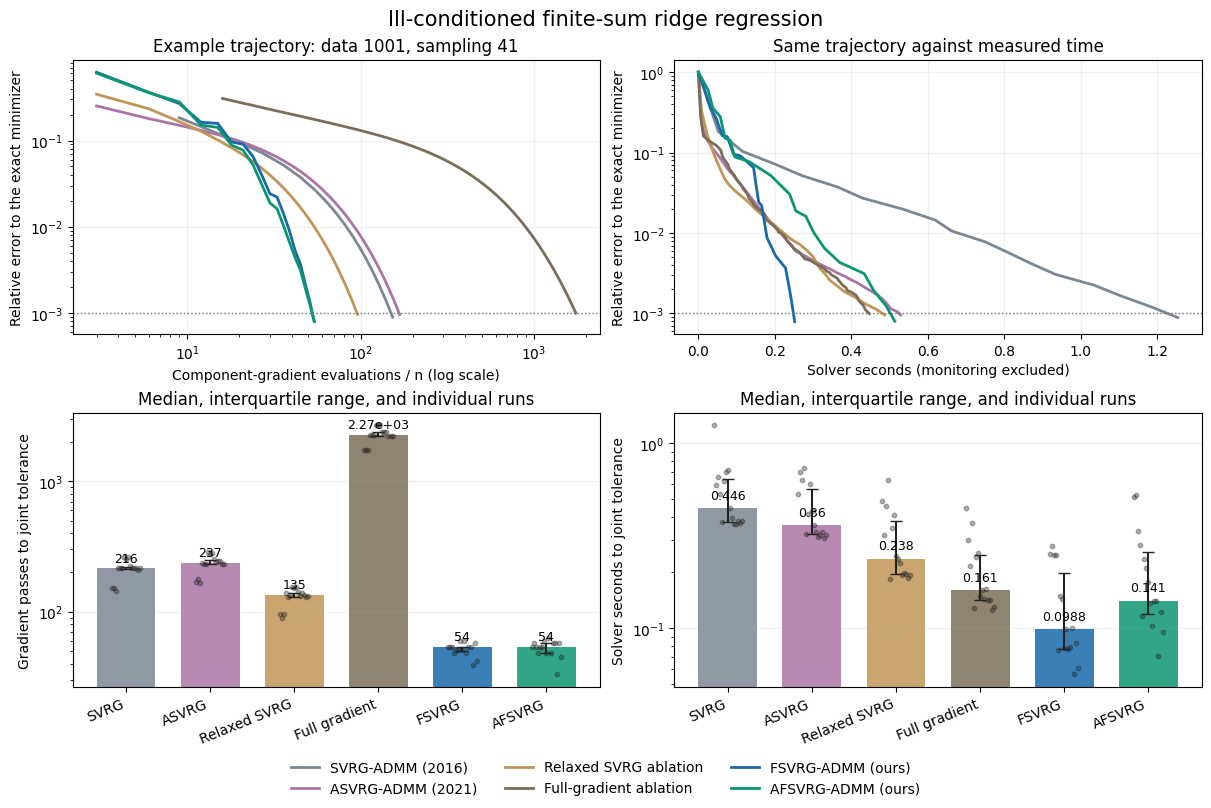


                 method  runs  successes  median_passes  min_passes  max_passes  median_solver_seconds  max_final_error  max_final_feasibility
      SVRG-ADMM (2016)    15         15          216.0       144.0       261.0               0.446209         0.000890           9.648426e-08
     ASVRG-ADMM (2021)    15         15          237.0       165.0       288.0               0.359550         0.000996           2.764141e-06
 Relaxed SVRG ablation    15         15          135.0        90.0       156.0               0.238001         0.000981           2.829847e-05
Full-gradient ablation    15         15         2272.0      1744.0      2704.0               0.160852         0.000994           8.501985e-07
     FSVRG-ADMM (ours)    15         15           54.0        39.0        60.0               0.098836         0.000975           2.949250e-04
    AFSVRG-ADMM (ours)    15         15           54.0        33.0        63.0               0.141101         0.000940           7.027410e-04

   

In [ ]:
# "full": 5 datasets x 3 sampling seeds x 6 methods (the reported experiment).
# "quick": the first data/sampling pair, with all six methods.
MODE = "full"
OUTPUT_DIR = "fsvrg_advantage_results"
SHOW_PLOTS = True

context = threadpool_limits(limits=1) if threadpool_limits else nullcontext()
with context:
    results, summary, paired_comparisons = benchmark(
        mode=MODE, output=OUTPUT_DIR, show=SHOW_PLOTS
    )


## 4. Results and paired comparisons


In [ ]:
try:
    from IPython.display import display
except ImportError:
    display = print

display(summary)
display(paired_comparisons)
print("All runs reached the target:", bool(results.reached_tolerance.all()))
print("Compare gradient passes first. Colab timings can vary with its CPU and load.")


,method,runs,successes,median_passes,min_passes,max_passes,median_solver_seconds,max_final_error,max_final_feasibility
0,SVRG-ADMM (2016),15,15,216.0,144.0,261.0,0.446209,0.000890,9.648426e-08
1,ASVRG-ADMM (2021),15,15,237.0,165.0,288.0,0.359550,0.000996,2.764141e-06
2,Relaxed SVRG ablation,15,15,135.0,90.0,156.0,0.238001,0.000981,2.829847e-05
3,Full-gradient ablation,15,15,2272.0,1744.0,2704.0,0.160852,0.000994,8.501985e-07
4,FSVRG-ADMM (ours),15,15,54.0,39.0,60.0,0.098836,0.000975,2.949250e-04
5,AFSVRG-ADMM (ours),15,15,54.0,33.0,63.0,0.141101,0.000940,7.027410e-04


,proposed,baseline,pairs,both_succeeded,proposed_failures,baseline_failures,strict_work_wins,median_paired_work_ratio
0,FSVRG-ADMM (ours),SVRG-ADMM (2016),15,15,0,0,15,4.235294
1,FSVRG-ADMM (ours),ASVRG-ADMM (2021),15,15,0,0,15,4.588235
2,FSVRG-ADMM (ours),Relaxed SVRG ablation,15,15,0,0,15,2.600000
3,FSVRG-ADMM (ours),Full-gradient ablation,15,15,0,0,15,44.549020
4,AFSVRG-ADMM (ours),SVRG-ADMM (2016),15,15,0,0,15,4.000000
5,AFSVRG-ADMM (ours),ASVRG-ADMM (2021),15,15,0,0,15,4.333333
6,AFSVRG-ADMM (ours),Relaxed SVRG ablation,15,15,0,0,15,2.476190
7,AFSVRG-ADMM (ours),Full-gradient ablation,15,15,0,0,15,42.105263


All runs reached the target: True
Compare gradient passes first. Colab timings can vary with its CPU and load.


## 5. Export figures and numerical results


In [ ]:
import shutil

archive = shutil.make_archive("fsvrg_advantage_generated_results", "zip", OUTPUT_DIR)
print("Saved results archive:", archive)
# Optional in Colab: uncomment the next two lines to download the archive.
# from google.colab import files
# files.download(archive)


Saved results archive: /content/fsvrg_advantage_generated_results.zip
